# Law of Total Probability

Companion notebook for [The Law of Total Probability](../../notes/probability/total_probability.md).

If $B_1,\dots,B_n$ partition the sample space then $P(A)=\sum_i P(A\mid B_i)P(B_i)$. We apply it to draws without replacement, to a factory example, and to the urn problem from the note, and verify each by simulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from fractions import Fraction

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 3.5)

## 1. A reusable function

The function checks that the partition probabilities add to one and returns the weighted sum.

In [2]:
def total_probability(prior, likelihood):
    prior = np.asarray(prior, dtype=float)
    likelihood = np.asarray(likelihood, dtype=float)
    assert np.isclose(prior.sum(), 1.0), "partition probabilities must sum to 1"
    return float((prior * likelihood).sum())

# Factory: machine shares and defect rates
print("P(defective) =", total_probability([0.5, 0.3, 0.2], [0.02, 0.03, 0.05]))

P(defective) = 0.029


## 2. Second draw without replacement

A bag has 3 red, 4 blue, 5 green balls. Partition on the first ball's color:
$P(R_2)=\frac{2}{11}\frac{3}{12}+\frac{3}{11}\frac{4}{12}+\frac{3}{11}\frac{5}{12}=\frac14$, the same as $P(R_1)$.

In [3]:
exact = total_probability([3/12, 4/12, 5/12], [2/11, 3/11, 3/11])
bag = np.array([0]*3 + [1]*4 + [2]*5)       # 0 = red
second_red = np.mean([bag[rng.permutation(12)[1]] == 0 for _ in range(100_000)])
print("exact:", round(exact, 4), " simulated:", round(second_red, 4))

exact: 0.25  simulated: 0.2538


## 3. Two-stage experiment

Roll a die: on 1-2 draw from urn A (3 red, 1 blue), otherwise from urn B (1 red, 3 blue). The note's method gives $P(\text{red})=\frac13\cdot\frac34+\frac23\cdot\frac14=\frac5{12}$.

In [4]:
exact = total_probability([2/6, 4/6], [3/4, 1/4])
n = 200_000
die = rng.integers(1, 7, n)
p_red = np.where(die <= 2, 0.75, 0.25)
sim = (rng.random(n) < p_red).mean()
print("exact:", round(exact, 4), "(5/12 =", round(5/12, 4), ")  simulated:", round(sim, 4))

exact: 0.4167 (5/12 = 0.4167 )  simulated: 0.4153


## 4. Urns with white fraction $i/n$

With urns $0,\dots,n$ and white fraction $i/n$ in urn $i$, the note shows $P(\text{white})=\tfrac12$ for every $n$. We check several $n$.

In [5]:
for n in (1, 2, 4, 10, 100):
    i = np.arange(n + 1)
    print(n, total_probability(np.full(n + 1, 1 / (n + 1)), i / n))

1 0.5
2 0.5
4 0.5
10 0.5
100 0.5000000000000001


## 5. A Markov weather chain

If $P(\text{rain today})=p$, then $P(\text{rain tomorrow})=0.6p+0.2(1-p)$. Applying the law repeatedly converges to the stationary value solving $p=0.6p+0.2(1-p)$, i.e. $p=0.2/0.6=1/3$.

[0.3, 0.32, 0.328, 0.3312] ... 0.3333 (limit 1/3 = 0.3333 )


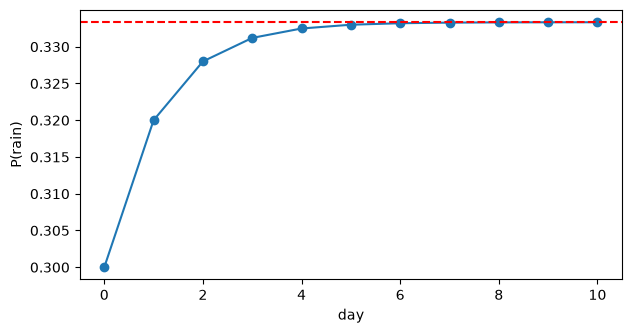

In [6]:
p = 0.3
path = [p]
for day in range(10):
    p = 0.6 * p + 0.2 * (1 - p)
    path.append(p)
print([round(x, 4) for x in path[:4]], "...", round(path[-1], 4), "(limit 1/3 =", round(1/3, 4), ")")

plt.plot(path, marker="o")
plt.axhline(1/3, color="red", linestyle="--")
plt.xlabel("day"); plt.ylabel("P(rain)")
plt.show()